this script creates data for matching analysis that each unit is single authors.

The output contains:
- author_id
- discipline classification of authors: derived from the publication record between 2008-2020
- gender information: "unk" is removed from the data
- yfp: year of first publication
- npub: number of publication up to 2020
- F,L,M: number of times being first(last, middle) author in international collaboration between 2008-2020
- Code: nationality of authors: multiple nationality are counted both
- ingroup: income group of the countries

In [31]:
author_meta.head()

,cluster_id,dis,gender,yfp,npub,F,L,M,intcnt,Code,ingroup
0,20009795,51,F,2008,5,2,0,0,2,JPN,H
1,29411586,51,M,2000,74,3,0,5,8,JPN,H
2,1221298,51,M,1980,21,0,0,2,2,JPN,H
3,38679117,51,F,1980,56,0,2,2,4,JPN,H
5,22736843,26,M,2008,1,0,0,1,1,JPN,H


In [1]:
import pandas as pd
import numpy as np
from collections import Counter
import seaborn as sns

In [2]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl"
pub_path="../../data/dropbox/LaborDivision/Data/deriveddata/pub_detail.pkl"
info_path='../../data/dropbox/LaborDivision/Data/cleanedraw/author_info.pkl'
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_meta.csv'

In [3]:
output_path='../../data/dropbox/LaborDivision/Data/deriveddata/matching/author_meta.csv'

In [4]:
author_df=pd.read_pickle(author_path)
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [5]:
pub_all=pd.read_pickle(pub_path)
pub_all.head()

,id,year,dis,alpha,teamsize,int
0,38579295,2012,1,no,4,0
1,38579296,2012,120,no,4,0
2,38579297,2012,84,no,4,1
3,38579302,2012,55,no,4,0
4,38579305,2012,43,no,4,0


In [6]:
info_df=pd.read_pickle(info_path)
info_df.head()

,cluster_id,yfp,npub,gender
0,689940,2008,1,unk
1,44823147,2008,1,unk
2,27676457,2011,1,M
3,59751143,2018,1,F
4,59894652,2004,8,M


### derive the discipline of authors based on the publication history

In [7]:
author_all=pd.read_pickle("../../data/dropbox/LaborDivision/Data/cleanedraw/pub_authorid.pkl")
author_all.head()

,id,seqno,cluster_id
0,75871588,2,689940
1,53614014,3,44823147
2,78030267,1,27676457
3,54383423,2,59751143
4,32237142,3,59894652


In [8]:
author_all['id']=author_all['id'].astype('str')

In [9]:
author_all=author_all[['id','cluster_id']].drop_duplicates()#select unique paper-author pair
author_all_dis=author_all[['cluster_id','id']].merge(pub_all[['id','dis']],on='id')#add discipline information to author_pub pair

In [10]:
#group the discipline into a list
author_all_dis=author_all_dis.groupby(['cluster_id'])['dis'].apply(list).reset_index(name='dislist')
#find the most common discipine in the list
author_all_dis['dis']=author_all_dis['dislist'].apply(lambda x:Counter(x).most_common()[0][0])

In [12]:
author_all_dis['cluster_id']=author_all_dis['cluster_id'].astype('str')

In [14]:
author_all_dis=author_all_dis.dropna()

### derive the number of international collaboration the researcher has during 2008-2020

In [15]:
pub_int=pub_all[pub_all.int==1]#select international publication including alphabetically ordered publications
author_int=author_all[author_all['id'].isin(pub_int['id'].values)] #select author-pub pair if the publication is international
author_int=author_int.groupby(['cluster_id'])['id'].size().reset_index(name='intcnt')

In [16]:
author_int['cluster_id']=author_int['cluster_id'].astype('str')

### count the number of roles each author played in international collaboration for noalpha authors in noalpha papers

In [17]:
role_df=author_df.groupby(['cluster_id','role']).size().reset_index(name='count')
role_df=role_df.pivot_table(index='cluster_id',columns='role',values='count',fill_value=0).reset_index()
role_df.head()

role,cluster_id,F,L,M
0,10000014,0,0,1
1,10000035,0,0,1
2,10000056,0,0,1
3,1000008,0,0,1
4,10000110,0,0,1


### derive the nationality of researchers. For researcher with multiple nationalities, they are counted multiple times

In [18]:
nal_df=author_df[['cluster_id','Code']]
nal_df=nal_df.drop_duplicates() # multi national authors are double counted

In [60]:
numdup=len(nal_df[nal_df.duplicated(subset=['cluster_id'])]['cluster_id'].unique())#number of unique authors have multiple nations
numauthor=len(author_df['cluster_id'].unique())#number of unique authors that are in the noalpha papers
numdup/numauthor #the share of authors that have multiple nationalities

0.0565101599343113

In [22]:
author_meta=author_df[['cluster_id']].drop_duplicates().dropna()
author_meta=author_meta.merge(nal_df,on='cluster_id') #multi national authors are double counted
author_meta=author_meta.merge(info_df,on='cluster_id',how='left')
author_meta=author_meta.merge(role_df,on='cluster_id',how='left')
author_meta=author_meta.merge(author_int,on='cluster_id',how='left')
author_meta=author_meta.merge(author_all_dis[['cluster_id','dis']],on='cluster_id',how='left')

In [30]:
author_meta.head()

,cluster_id,dis,gender,yfp,npub,F,L,M,intcnt,Code,ingroup
0,20009795,51,F,2008,5,2,0,0,2,JPN,H
1,29411586,51,M,2000,74,3,0,5,8,JPN,H
2,1221298,51,M,1980,21,0,0,2,2,JPN,H
3,38679117,51,F,1980,56,0,2,2,4,JPN,H
5,22736843,26,M,2008,1,0,0,1,1,JPN,H


In [24]:
ingroup_df=pd.read_csv(ingroup_path)[['Code','ingroup_08-20']]
ingroup_df=ingroup_df.drop_duplicates()
ingroup_df.head()

,Code,ingroup_08-20
0,AFG,L
1,ALB,UM
2,DZA,UM
3,AND,H
4,AGO,LM


In [25]:
author_meta=author_meta.merge(ingroup_df,on='Code')

In [26]:
author_meta=author_meta[['cluster_id','dis','gender','yfp','npub','F','L','M','intcnt','Code','ingroup_08-20']]

In [27]:
author_meta=author_meta.rename(columns={'ingroup_08-20':'ingroup'})

In [28]:
author_meta=author_meta[author_meta.gender!='unk']

In [29]:
author_meta.to_csv(output_path,index=False)

In [4]:
df=pd.read_csv(output_path)

<AxesSubplot:xlabel='npub', ylabel='Density'>

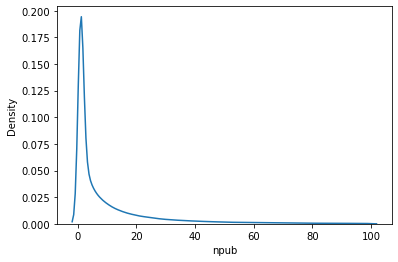

In [11]:
sns.kdeplot(x='npub',data=df[(df['Code']=='USA')&(df.npub<100)])